## Gradient Descent

In [1]:
import numpy as np

"""Calculates the next theta based on the previous one"""
def NextTheta(eta: float, X_b: np.ndarray,
    theta: np.ndarray, y: np.ndarray):

    m = len(X_b)
    gradients = 2 / m * X_b.T @ (X_b @ theta - y)
    theta = theta - eta * gradients
    
    return theta

In [2]:
def GradientDescentTheta(eta: float, n_epochs: int, random_seed: int, X_b: np.ndarray,
                        y: np.ndarray):
    if(n_epochs <= 0):
        raise AttributeError("The number of epochs must be positive!")
    np.random.seed(random_seed)

    if(y.ndim == 2):
        theta = np.random.randn(X_b.shape[1], 1)
    else:
        theta = np.random.randn(X_b.shape[1])
    
    for epoch in range(n_epochs):
        theta = NextTheta(eta,X_b,theta,y)

    return theta


In [3]:
np.random.seed(42)
m = 100
X = 2 * np.random.rand(m, 1)
y = 4 + 3 * X + np.random.randn(m, 1)

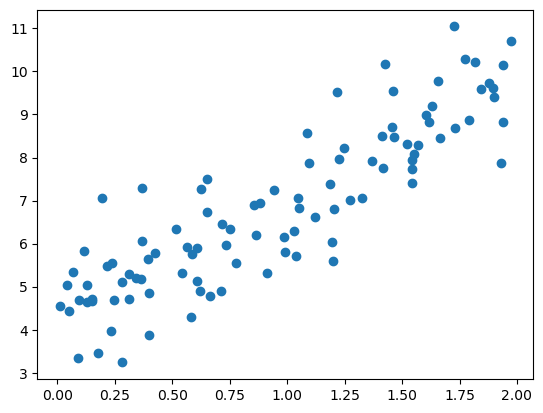

In [4]:
import matplotlib.pyplot as plt

plt.scatter(X,y)
plt.show()

In [5]:
X_b = np.c_[np.ones((m, 1)), X]
print(GradientDescentTheta(0.1,1000,42,X_b,y))

[[4.21509616]
 [2.77011339]]


## Softmax Regression

In [6]:
def NextSoftmaxTheta(eta: float, X_b: np.ndarray,
    theta: np.ndarray, P: np.ndarray, one_hot_y: np.ndarray):

    m = len(X_b)
    gradients = 1 / m * X_b.T @ (P - one_hot_y)
    theta = theta - eta * gradients
    
    return theta

In [7]:
def GradientDescentSoftmaxTheta(eta: float, n_epochs: int, random_seed: int, X_b: np.ndarray,
                        y: np.ndarray, K: int, y_val: np.ndarray, X_val: np.ndarray,
                        patience: int):
    if(n_epochs <= 0):
        raise AttributeError("The number of epochs must be positive!")
    np.random.seed(random_seed)

    theta = np.random.randn(X_b.shape[1],K)
    one_hot_y = np.eye(K)[y]
    one_hot_y_val = np.eye(K)[y_val]
    
    best_val_loss = np.inf
    best_theta = theta.copy()

    epochs_without_improvement = 0
    
    for epoch in range(n_epochs):
        scores = X_b @ theta
        exp_scores = np.exp(scores) 
        P = exp_scores / np.sum(exp_scores, axis=1, keepdims=True)

        scores_val = X_val @ theta
        exp_scores_val = np.exp(scores_val) 
        P_val = exp_scores_val / np.sum(exp_scores_val, axis=1, keepdims=True)

        val_loss = -np.mean(np.sum(one_hot_y_val * np.log(P_val + 1e-7), axis=1))

        if(best_val_loss > val_loss):
            best_val_loss = val_loss
            best_theta = theta.copy()
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                break

        if(patience == 0):
            print(f"Stopped early at epoch {epoch}")
            break
        if epoch % 10000 == 0:
            print(epoch, val_loss)
        
        theta = NextSoftmaxTheta(eta,X_b,theta=theta,P=P,one_hot_y=one_hot_y)

    return best_theta

## Using Softmax on Iris

In [8]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

iris = load_iris(as_frame=True)
X = iris.data[["petal length (cm)", "petal width (cm)"]].values
X_b = np.c_[np.ones((len(X), 1)), X]
y = iris["target"].values
X_temp, X_test, y_temp, y_test = train_test_split(
    X_b, y, test_size=0.2, random_state=42, stratify=y)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp)

print(X_train.shape, X_val.shape)


(90, 3) (30, 3)


In [9]:
theta = GradientDescentSoftmaxTheta(0.1,1000000,42,X_train,y_train,3,y_val,X_val,120)

0 7.714338396071974
10000 0.23406613364613557
20000 0.21868207805790976
30000 0.21309702241528905
40000 0.21011647242054493
50000 0.20817667988980773
60000 0.2067716106228578
70000 0.20569550591658173
80000 0.2048486971321403
90000 0.20417506111980688
100000 0.20363871679084605
110000 0.20321436010006239
120000 0.2028828741010858
130000 0.20262915231154732
140000 0.20244091684998722
150000 0.20230801392815637
160000 0.2022219547820127
170000 0.20217559277507594


In [ ]:
(np.argmax(X_test @ theta, axis=1) == y_test).mean()

np.float64(0.9333333333333333)